<a href="https://colab.research.google.com/github/Briggernaut/MusicLeagueAnalysis/blob/main/MusicLeagueAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clone and Config

In [1]:
#@title Clone repo
import os, sys
if 'google.colab' in sys.modules:
    if not os.path.exists('MusicLeagueAnalysis'):
        !git clone https://github.com/Briggernaut/MusicLeagueAnalysis
    %cd MusicLeagueAnalysis

Cloning into 'MusicLeagueAnalysis'...
remote: Enumerating objects: 66, done.
remote: Counting objects: 100% (66/66), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 66 (delta 28), reused 15 (delta 1), pack-reused 0 (from 0)
Receiving objects: 100% (66/66), 1.93 MiB | 9.27 MiB/s, done.
Resolving deltas: 100% (28/28), done.
/content/MusicLeagueAnalysis


In [31]:
#@title Select and Read in Season Data
#load dataframes
import pandas as pd
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np

SEASON = "Season 2" #@param ["All", "Season 1", "Season 2"] {allow-input: true}
DATA_DIR = "data"

#formatting
BOLD = '\033[1m'
RESET = '\033[0m'

# Convenience functions, move to lib
def get_player_name_from_id(id):
    return competitors_df.loc[competitors_df['ID']==id,'Name'].values[0]

def get_round_name_from_id(id):
    return rounds_df.loc[rounds_df['ID']==id,'Name'].values[0]

# Find every folder that has the four needed CSVs
REQUIRED = ['competitors.csv', 'rounds.csv', 'submissions.csv', 'votes.csv']
def getSeasons():
  out = []
  for d in os.listdir(DATA_DIR):
    if os.path.isdir(os.path.join(DATA_DIR, d)):
      for f in REQUIRED:
        if not os.path.exists(os.path.join(DATA_DIR, d, f)):
          break
      else:
        out.append(d)
  return out

available_seasons = sorted(getSeasons())
print('Available seasons:', available_seasons)

if SEASON == "All":
    selected_seasons = available_seasons
elif SEASON in available_seasons:
    selected_seasons = [SEASON]

print('Selected seasons:', selected_seasons)

def load_seasons(filename):
    frames = []
    for season in selected_seasons:
        df = pd.read_csv(os.path.join(DATA_DIR, season, filename))
        df['Season'] = season
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

competitors_df = load_seasons('competitors.csv')
rounds_df = load_seasons('rounds.csv')
submissions_df = load_seasons('submissions.csv')
votes_df = load_seasons('votes.csv')

# convenience definitions
playerIds = competitors_df['ID']
roundIds = rounds_df['ID']

# submissions_df does not have a unique key, make one for easier lookups
submissions_df['uid'] = submissions_df['Spotify URI'] + ' ' + submissions_df['Round ID']
votes_df['uid'] = votes_df['Spotify URI'] + ' ' + votes_df['Round ID']

# Add a column in votes_df for submitted_by_id
lookup_series = submissions_df.set_index('uid')['Submitter ID']
votes_df['Submitter ID'] = votes_df['uid'].map(lookup_series)

# Print Datafram column headers
print('Competitors: ',competitors_df.columns.to_numpy().tolist())
print('Rounds: ',rounds_df.columns.to_numpy().tolist())
print('Submissions: ',submissions_df.columns.to_numpy().tolist())
print('Votes: ',votes_df.columns.to_numpy().tolist())

Available seasons: ['Season 1', 'Season 2']
Selected seasons: ['Season 2']
Competitors:  ['ID', 'Name', 'Season']
Rounds:  ['ID', 'Created', 'Name', 'Description', 'Playlist URL', 'Season']
Submissions:  ['Spotify URI', 'Title', 'Album', 'Artist(s)', 'Submitter ID', 'Created', 'Comment', 'Round ID', 'Visible To Voters', 'Season', 'uid']
Votes:  ['Spotify URI', 'Voter ID', 'Created', 'Points Assigned', 'Comment', 'Round ID', 'Season', 'uid', 'Submitter ID']


In [28]:
#@title Songs by Season and Round
songs = (submissions_df
         .merge(rounds_df[['ID', 'Name', 'Created', 'Season']]
                .rename(columns={'ID': 'Round ID', 'Name': 'Round', 'Created': 'Round Created'}),
                on=['Round ID', 'Season'], how='left')
         .sort_values(['Season', 'Round Created', 'Created']))

for season, s_grp in songs.groupby('Season', sort=False):
    print(f"\n{BOLD}===== {season} ====={RESET}")
    for rnd, r_grp in s_grp.groupby('Round', sort=False):
        print(f"\n{BOLD}{rnd}{RESET}")
        for _, r in r_grp.iterrows():
            print(f"  {r['Title']} — {r['Artist(s)']}")


===== Season 1 =====

Water
  Bismarck — Sabaton
  Sloop John B — The Beach Boys
  Drink Up Me Hearties Yo Ho - From "Pirates of the Caribbean: At World's End"/Score — Hans Zimmer
  Surfer Girl — Home Grown
  Ship To Wreck — Florence + The Machine
  Floats My Boat — Aer
  Breakers Roar — Sturgill Simpson
  Rainy Night in Georgia — Tony Joe White
  Waterfalls — TLC
  Compass — Wovenwar

Favourite song released before you were born
  Ooh La La — Faces
  Beat It — Michael Jackson
  Hotel California - 2013 Remaster — Eagles
  Ramble On - 1990 Remaster — Led Zeppelin
  Smells Like Teen Spirit — Nirvana
  Yesterday - Remastered 2009 — The Beatles
  Me and Julio Down by the Schoolyard — Paul Simon
  American Pie — Don McLean
  Stand By Me — Ben E. King
  In the Summertime — Mungo Jerry
  Step by Step — New Kids On The Block
  Sweet Child O' Mine — Guns N' Roses

getting ready to win something / pump you up music
  Waka Waka (This Time for Africa) [The Official 2010 FIFA World Cup (TM) Song] 

# Analysis

In [3]:
#@title Songs Submitted by Each User (interactive)
#list of songs submitted by each user
songs_submitted = {}
for player in playerIds:
    # Returns the title and artist of every submission from player
    song_list = submissions_df.loc[submissions_df['Submitter ID'] == player, ['Title','Artist(s)']]
    # smush the artist and title together
    song_list['formatted'] = song_list['Title'].str.cat(song_list['Artist(s)'], sep=' by ')
    # turn player id to player name
    player_name = get_player_name_from_id(player)
    # drop the ide field
    song_list = song_list.iloc[:, 1:]
    # dict of list of songs index by player name
    songs_submitted[player_name] = song_list['formatted'].tolist()

#sort the dict alphabetically to make it pretty
songs_submitted = dict(sorted(songs_submitted.items()))

# Define the event handler function for drop down
def on_change(change):
    if change['type'] == 'change' and change['name'] == 'value':
        with output:
            output.clear_output() # Clear previous text
            print(f"{BOLD}Player {change['new']} submitted the following songs:{RESET}")
            print(*songs_submitted[change['new']], sep="\n")

# Create the dropdown
dropdown = widgets.Dropdown(
    options=list(songs_submitted),
    description='Select a player:',
    style={'description_width': 'initial'},
    disabled=False,
)
output = widgets.Output()

# Bind the function to the dropdown's value changes
dropdown.observe(on_change)

# Display both the dropdown and the output container
display(dropdown, output)

Dropdown(description='Select a player:', options=('Adam Kestian', 'Ali N.', 'Andrew', 'Andy Curtis', 'Brigette…

Output()

In [29]:
#@title Calculate player stats
player_votes_stats = []
for player in playerIds:
    # Sum all votes given to a player
    totalVotes = votes_df.loc[votes_df['Submitter ID'] == player, 'Points Assigned'].sum()
    # find the number of rounds they participated in
    count = (submissions_df['Submitter ID'] == player).sum()
    #print (player +' got '+ str(totalVotes) +' votes '+' and participated in '+str(count)+'rounds')
    # Append simple dictionaries to a list
    player_votes_stats.append({'Name': get_player_name_from_id(player), 'Votes For': totalVotes, 'Rounds Participated':count})

# Convert the whole list to a DataFrame all at once
player_stat_df = pd.DataFrame(player_votes_stats)
player_stat_df['Votes per Round'] = player_stat_df['Votes For']/player_stat_df['Rounds Participated']


In [30]:
#@title Player Song Results
import pandas as pd
import numpy as np
import ipywidgets as widgets
from IPython.display import display, clear_output

def elide(val, max_len=40):
    s = str(val)
    return s[:max_len-3] + '...' if len(s) > max_len else s

# 1. Chronologically sort rounds
sorted_rounds = rounds_df.sort_values(by='Created').reset_index(drop=True)
round_id_order = sorted_rounds['ID'].tolist()
round_name_map = dict(zip(rounds_df['ID'], rounds_df['Name']))

# 2. Get unique participants sorted case-insensitively
participants = sorted(competitors_df['Name'].unique(), key=lambda s: s.lower())
default_player = 'mcapewell' if 'mcapewell' in participants else participants[0]

# Precompute overall round results for positions and season standings
round_votes = votes_df.groupby(['Round ID', 'Submitter ID'])['Points Assigned'].sum().reset_index()

voter_counts = votes_df.groupby(['Round ID', 'Submitter ID'])['Voter ID'].nunique().reset_index(name='Voter Count')
round_votes = pd.merge(round_votes, voter_counts, on=['Round ID', 'Submitter ID'], how='left')

# Generate a dict tracking rankings per round
round_ranks = {}
for r_id in round_id_order:
    r_data = round_votes[round_votes['Round ID'] == r_id].copy()
    if r_data.empty:
        continue
    r_data = r_data.sort_values(by='Points Assigned', ascending=False).reset_index(drop=True)
    r_data['Rank'] = r_data['Points Assigned'].rank(ascending=False, method='min').astype(int)
    total_participants = len(r_data)
    round_ranks[r_id] = {
        row['Submitter ID']: (row['Rank'], total_participants, row['Points Assigned'], row['Voter Count'])
        for _, row in r_data.iterrows()
    }

# Calculate cumulative running rank after each round, keeping track of leaders and point gaps
cumulative_points = {}
season_rank_at_round = {} # Maps (player_id, round_id) -> "rank/total"
running_total_at_round = {} # Maps (player_id, round_id) -> total_points
trailing_by_at_round = {} # Maps (player_id, round_id) -> string representation like "30 (15%)"

for r_idx, r_id in enumerate(round_id_order):
    r_data = round_votes[round_votes['Round ID'] == r_id]
    for _, row in r_data.iterrows():
        p_id = row['Submitter ID']
        cumulative_points[p_id] = cumulative_points.get(p_id, 0) + row['Points Assigned']
        running_total_at_round[(p_id, r_id)] = cumulative_points[p_id]

    if cumulative_points:
        sorted_cum = sorted(cumulative_points.items(), key=lambda x: x[1], reverse=True)
        leader_id, leader_points = sorted_cum[0]

        cum_df = pd.DataFrame(sorted_cum, columns=['Player ID', 'CumPoints'])
        cum_df['Rank'] = cum_df['CumPoints'].rank(ascending=False, method='min').astype(int)
        total_cum_players = len(cum_df)

        for _, row in cum_df.iterrows():
            curr_player_id = row['Player ID']
            curr_points = row['CumPoints']
            season_rank_at_round[(curr_player_id, r_id)] = f"{row['Rank']}/{total_cum_players}"

            if curr_player_id == leader_id:
                trailing_by_at_round[(curr_player_id, r_id)] = "-"
            else:
                gap = leader_points - curr_points
                pct = (gap / leader_points * 100) if leader_points > 0 else 0.0
                trailing_by_at_round[(curr_player_id, r_id)] = f"{int(gap)} ({pct:.0f}%)"

# Dropdown widget setup
dropdown = widgets.Dropdown(
    options=participants,
    value=default_player,
    description='Player:',
    disabled=False,
)
output = widgets.Output()

def update_dashboard(change):
    with output:
        clear_output(wait=True)
        player_name = change['new']
        p_id = competitors_df.loc[competitors_df['Name'] == player_name, 'ID'].values[0]

        table_data = []
        for week_num, r_id in enumerate(round_id_order, 1):
            # Get player submission for this round
            sub = submissions_df[(submissions_df['Round ID'] == r_id) & (submissions_df['Submitter ID'] == p_id)]
            if sub.empty:
                continue

            sub_row = sub.iloc[0]
            round_name = elide(round_name_map.get(r_id, r_id))
            song_title = elide(sub_row['Title'])
            artist_name = elide(sub_row['Artist(s)'])

            # Retrieve rankings & scores
            r_stats = round_ranks.get(r_id, {}).get(p_id, (0, 0, 0, 0))
            rank_in_round = f"{int(r_stats[0])}/{r_stats[1]}" if r_stats[1] > 0 else "N/A"
            votes_received = int(r_stats[2])
            voters_count = int(r_stats[3])

            cum_rank = season_rank_at_round.get((p_id, r_id), "N/A")
            tot_points = running_total_at_round.get((p_id, r_id), 0)
            trailing_str = trailing_by_at_round.get((p_id, r_id), "-")

            table_data.append({
                'Week #': week_num,
                'Week Title': round_name,
                'Song Title': song_title,
                'Artist Name': artist_name,
                'Round Rank': rank_in_round,
                'Votes': votes_received,
                'Voters': voters_count,
                'Tot': tot_points,
                'Trailing 1st by': trailing_str,
                'Season Rank After Round': cum_rank
            })

        df = pd.DataFrame(table_data)
        if not df.empty:
            display(df.style.hide(axis='index'))
        else:
            print("No submissions found for this player in the selected season.")

dropdown.observe(update_dashboard, names='value')
display(dropdown, output)

# Trigger initial run
update_dashboard({'new': default_player})

Dropdown(description='Player:', index=29, options=('Adam Kestian', 'Ali N.', 'Andrew', 'Andy Curtis', 'Brigett…

Output()

## Votes per Round


In [6]:
#@title Display list of best votes per round
# sort by votes/round
display_df = player_stat_df[['Name', 'Votes per Round']].sort_values(by='Votes per Round', ascending=False)
# display list
display(display_df.style.hide(axis="index"))

Name,Votes per Round
jandrews,39.181818
Andrew,38.333333
De Wolfe,36.280000
Isaiah Freed,34.440000
mandeepkundal,32.960000
peter mccomb,32.833333
Katie,31.913043
KLee,31.578947
Adam Kestian,31.440000
William Dullemond,31.400000


In [7]:
#@title Player results table
import pandas as pd
import numpy as np

# 1. Calculate votes per player per round
votes_per_round = votes_df.groupby(['Round ID', 'Submitter ID'])['Points Assigned'].sum().reset_index()

# 2. Determine round placements (1st, 2nd, 3rd)
# We rank players within each round. method='min' handles ties, but let's assign dense ranking.
votes_per_round['Rank'] = votes_per_round.groupby('Round ID')['Points Assigned'].rank(ascending=False, method='min')

# 3. Aggregate player performance across all rounds
player_stats = []
for player in playerIds:
    player_name = get_player_name_from_id(player)

    # Get all round results for this player
    player_rounds = votes_per_round[votes_per_round['Submitter ID'] == player]

    weeks_participated = len(player_rounds)

    if weeks_participated > 0:
        avg_votes = player_rounds['Points Assigned'].mean()
        std_votes = player_rounds['Points Assigned'].std()
        # Handle cases with only 1 week participated where std dev is NaN
        if pd.isna(std_votes):
            std_votes = 0.0

        # Count 1st, 2nd, and 3rd place finishes
        weeks_won = (player_rounds['Rank'] == 1).sum()
        weeks_2nd = (player_rounds['Rank'] == 2).sum()
        weeks_3rd = (player_rounds['Rank'] == 3).sum()
    else:
        avg_votes = 0.0
        std_votes = 0.0
        weeks_won = 0
        weeks_2nd = 0
        weeks_3rd = 0

    player_stats.append({
        'Name': player_name,
        'Weeks Participated': weeks_participated,
        'Avg Votes/Week': avg_votes,
        'Std Dev Votes': std_votes,
        '1st Place Finishes': weeks_won,
        '2nd Place Finishes': weeks_2nd,
        '3rd Place Finishes': weeks_3rd
    })

# Convert to DataFrame and sort by Average Votes descending
player_summary_df = pd.DataFrame(player_stats).sort_values(by='Avg Votes/Week', ascending=False)

# Display the styled dataframe
display(player_summary_df.style.format({
    'Avg Votes/Week': '{:.2f}',
    'Std Dev Votes': '{:.2f}'
}).hide(axis='index'))

Name,Weeks Participated,Avg Votes/Week,Std Dev Votes,1st Place Finishes,2nd Place Finishes,3rd Place Finishes
jandrews,11,39.18,13.60,2,1,1
Andrew,6,38.33,17.55,1,1,1
De Wolfe,25,36.28,10.63,1,2,2
Isaiah Freed,25,34.44,9.37,2,1,1
mandeepkundal,25,32.96,11.73,3,1,1
peter mccomb,24,32.83,11.23,2,2,1
Katie,23,31.91,12.22,1,2,0
KLee,19,31.58,10.12,0,0,2
Adam Kestian,25,31.44,13.13,2,1,1
William Dullemond,25,31.40,11.55,2,0,2


Players with perfect attendance:
Isaiah Freed
mandeepkundal
Mick
Hman
Matoos
William Dullemond
Brigette
De Wolfe
katspjs
mcapewell
Adam Kestian

Players who forgot to vote after having submitted a song:


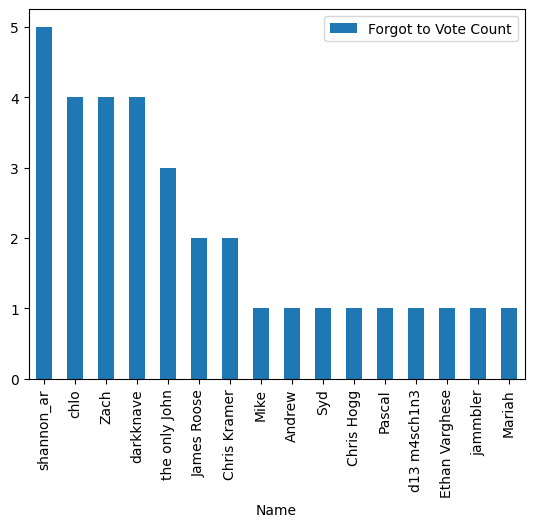

In [8]:
#@title Calculate participation stats
# How many rounds did each player not submit or not vote in?
player_attendance_stats=[]
for player in playerIds:
    rounds_submitted = submissions_df.loc[(submissions_df['Submitter ID'] == player),'Round ID'].tolist()
    rounds_not_submitted  = list(set(roundIds) - set(rounds_submitted))
    # rounds where user submitted but did not vote
    rounds_voted = votes_df.loc[(votes_df['Voter ID'] == player),'Round ID'].tolist()
    # list of rounds, remove those where user voted, remove those where the user did not submit
    rounds_forgot_to_vote = list(set(roundIds) - set(rounds_voted)-set(rounds_not_submitted))
    #convert ids to names
    rounds_submitted = [get_round_name_from_id(round_id) for round_id in rounds_submitted]
    rounds_not_submitted = [get_round_name_from_id(round_id) for round_id in rounds_not_submitted]
    rounds_forgot_to_vote = [get_round_name_from_id(round_id) for round_id in rounds_forgot_to_vote]
    player_attendance_stats.append({'Name': get_player_name_from_id(player), 'Rounds Not Submitted': rounds_not_submitted, 'Forgot to Vote':rounds_forgot_to_vote, 'Perfect Attendance':(len(rounds_not_submitted)==0 and len(rounds_forgot_to_vote)==0) })
player_attendance_df = pd.DataFrame(player_attendance_stats)
#makea column counting how many rounds a player forgot to vote
player_attendance_df['Forgot to Vote Count'] = player_attendance_df['Forgot to Vote'].str.len()
#print(player_attendance_df)
perfect_attendance_list = player_attendance_df.loc[(player_attendance_df['Perfect Attendance'] == True),'Name'].tolist()
print(f"{BOLD}Players with perfect attendance:{RESET}")
print(*perfect_attendance_list, sep="\n")

print(f"\n{BOLD}Players who forgot to vote after having submitted a song:{RESET}")
display_df = player_attendance_df.loc[(player_attendance_df['Forgot to Vote Count'] > 0)].sort_values(by='Forgot to Vote Count', ascending=False)
display_df.plot.bar(x='Name', y='Forgot to Vote Count', rot=90);

Name,Winner,Highest Score,Average Score,Most Votes,Submitted Last,Voted Last
Historical songs,jammbler,48,26.000000,7,mcapewell,shannon_ar
Nothing' but country,William Dullemond,46,26.000000,26,Mike,shannon_ar
Weather Elements,mandeepkundal,52,27.931034,11,James Roose,Mike
Festive but Forgotten,William Dullemond,68,30.000000,10,d13 m4sch1n3,Zach
Songs from the first album you ever bought,James Roose,49,28.636364,10,mcapewell,the only John
Karaoke 80s hair bands,Matoos,56,28.888889,10,Katie,mandeepkundal
Your hype song for a Mario Kart race,Isaiah Freed,51,30.000000,13,De Wolfe,the only John
The Ultimate Valentine's Day Playlist,jammbler,42,27.857143,12,shannon_ar,the only John
Songs from popular 80s movies,peter mccomb,55,26.896552,18,the only John,d13 m4sch1n3
The universal language: music without lyrics,Adam Kestian,64,29.032258,30,d13 m4sch1n3,the only John


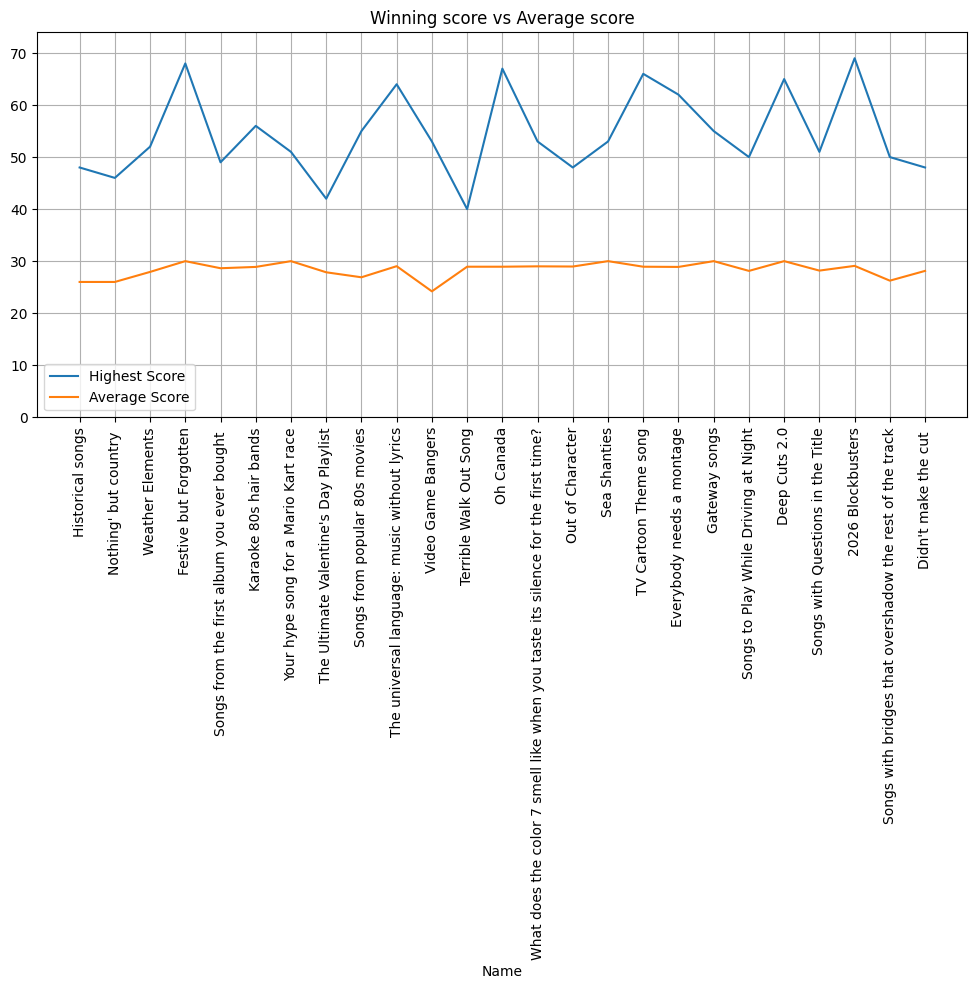

In [9]:
#@title Calculate Round stats
# Round stats who submitted last, who voted last, most votes given by a single person
round_stats = []
for roundId in roundIds:
    voted_last = get_player_name_from_id(votes_df.loc[votes_df[votes_df['Round ID'] == roundId]['Created'].idxmax(), 'Voter ID'])
    submitted_last = get_player_name_from_id(submissions_df.loc[submissions_df[submissions_df['Round ID'] == roundId]['Created'].idxmax(), 'Submitter ID'])
    #print ("voted last "+voted_last)
    #print ("submitted last "+submitted_last)
    most_points = votes_df.loc[votes_df[votes_df['Round ID'] == roundId]['Points Assigned'].idxmax(), 'Points Assigned']
    #print ("most points "+str(most_points))
    #gives us a df with URI and sum of votes
    round_results = votes_df.loc[votes_df['Round ID'] == roundId].groupby('Spotify URI', as_index=False)['Points Assigned'].sum()
    #print(round_results)
    ave_points_per_song= round_results['Points Assigned'].mean()
    #print ("average points per song "+str(ave_points_per_song))
    highest_score = round_results['Points Assigned'].max()
    #print('highest score '+str(highest_score))
    #get winner name from highest score
    winning_song = round_results.loc[round_results['Points Assigned']==highest_score,'Spotify URI'].values[0]
    #print('Winning song ' +winning_song)
    winner =  get_player_name_from_id(submissions_df.loc[(submissions_df['Round ID'] == roundId) & (submissions_df['Spotify URI'] == winning_song),'Submitter ID'].values[0])
    #TODO: need to score tiebreak by # voters, create a whole rank column for use later
    #print('Winner '+winner)
    round_stats.append({'Name': get_round_name_from_id(roundId), 'Winner': winner, 'Highest Score':highest_score, 'Average Score':ave_points_per_song, 'Most Votes':most_points,'Submitted Last': submitted_last, 'Voted Last':voted_last})

round_stats_df = pd.DataFrame(round_stats)
display(round_stats_df.style.hide(axis="index"))
score_v_average = round_stats_df[['Name', 'Highest Score','Average Score']]
ax= score_v_average.set_index('Name').plot.line(title='Winning score vs Average score', grid=True,figsize=(12, 5),ylim=(0, score_v_average['Highest Score'].max() + 5))
ax.set_xticks(np.arange(len(score_v_average)))
ax.set_xticklabels(score_v_average.Name, rotation=90)
plt.show()




```
# This is formatted as code
```

# Comments

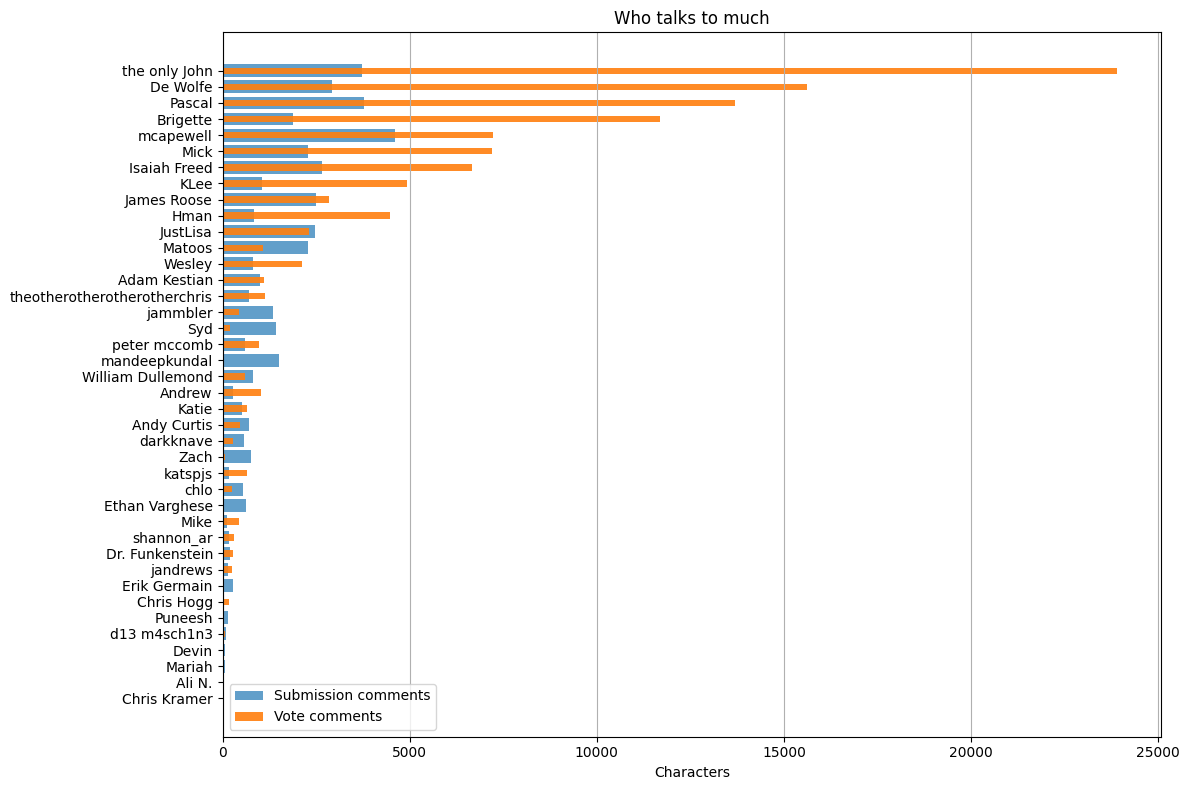

In [10]:
#@title Who Talks the Most
# Total characters each player wrote in submission comments and in voting comments overlaying each other

submission_chars = (submissions_df.assign(Chars=submissions_df['Comment'].fillna('').astype(str).str.len())
                    .groupby('Submitter ID')['Chars'].sum())
vote_chars = (votes_df.assign(Chars=votes_df['Comment'].fillna('').astype(str).str.len())
              .groupby('Voter ID')['Chars'].sum())

# Combine into one table - should add no char players
chars_df = pd.DataFrame({'Submissions': submission_chars, 'Votes': vote_chars}).fillna(0)
chars_df.index = [get_player_name_from_id(p) for p in chars_df.index]
chars_df = chars_df.loc[(chars_df['Submissions'] + chars_df['Votes']).sort_values().index]  # sort by verbosity

y = np.arange(len(chars_df))
fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(y, chars_df['Submissions'], height=0.8, label='Submission comments', alpha=0.7)
ax.barh(y, chars_df['Votes'], height=0.4, label='Vote comments', color='tab:orange', alpha=0.9)
ax.set_yticks(y)
ax.set_yticklabels(chars_df.index)
ax.set_xlabel('Characters')
ax.set_title('Who talks to much')
ax.grid(True, axis='x')
ax.legend()
plt.tight_layout()
plt.show()

In [11]:
# @title
# player stats (best round [placement or votes], worst round, who gave you most/least votes, rounds missed
# graph of votes received over round (with a running average line)
# rounds won
# number of comments left
# most emojis? count
# what place did they get in their own round?

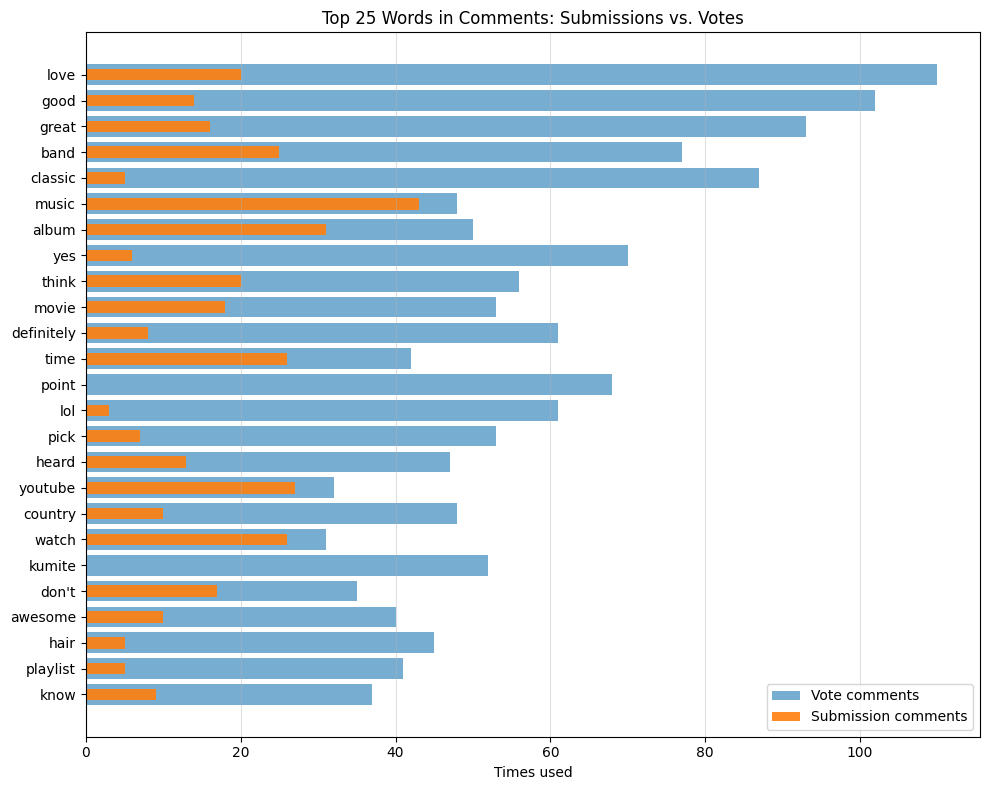

In [35]:
#@title Most Common Words in Comments (Submissions vs. Votes)
import re
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

top_n = 25  #@param {type:"integer"}
extra_stopwords = "song, songs, just, really, like, it's, com, https, i'm"  #@param {type:"string"}

stopwords = set(ENGLISH_STOP_WORDS) | {w.strip().lower() for w in extra_stopwords.split(',') if w.strip()}

def get_words(text):
    words = re.findall(r"[a-z']+", str(text).lower())
    words = [w.strip("'") for w in words]
    return [w for w in words if len(w) > 2 and w not in stopwords]

def count_words(series):
    return Counter(w for comment in series.dropna() for w in get_words(comment))

sub_counts = count_words(submissions_df['Comment'])
vote_counts = count_words(votes_df['Comment'])

# Pick top words by combined usage
total_counts = sub_counts + vote_counts
top_words = [w for w, _ in total_counts.most_common(top_n)]

df = pd.DataFrame({
    'Submissions': [sub_counts.get(w, 0) for w in top_words],
    'Votes': [vote_counts.get(w, 0) for w in top_words],
}, index=top_words)
df['Total'] = df['Submissions'] + df['Votes']
df = df.sort_values('Total')

# Overlaid horizontal bars
y = np.arange(len(df))
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(y, df['Votes'], height=0.8, alpha=0.6, label='Vote comments')
ax.barh(y, df['Submissions'], height=0.45, alpha=0.9, label='Submission comments')
ax.set_yticks(y)
ax.set_yticklabels(df.index)
ax.set_xlabel('Times used')
ax.set_title(f'Top {top_n} Words in Comments: Submissions vs. Votes')
ax.grid(axis='x', alpha=0.4)
ax.legend()
plt.tight_layout()
plt.show()

In [36]:
#@title Most Commented-on Songs
import pandas as pd
import numpy as np

def elide(val, max_len=40):
    s = str(val)
    return s[:max_len-3] + '...' if len(s) > max_len else s

# 1. Gather all comments related to a specific song submission (Spotify URI + Round ID)
# Comments can come from the submission itself and any votes cast on it.
comments_data = []

# Add submission comments if they exist
for _, row in submissions_df.iterrows():
    comm = row['Comment']
    if pd.notna(comm) and str(comm).strip() != '':
        comments_data.append({
            'Spotify URI': row['Spotify URI'],
            'Round ID': row['Round ID'],
            'Comment': str(comm)
        })

# Add vote comments if they exist
for _, row in votes_df.iterrows():
    comm = row['Comment']
    if pd.notna(comm) and str(comm).strip() != '':
        comments_data.append({
            'Spotify URI': row['Spotify URI'],
            'Round ID': row['Round ID'],
            'Comment': str(comm)
        })

comments_df_all = pd.DataFrame(comments_data)

# 2. Calculate comment statistics per unique song (defined by Spotify URI & Round ID)
if not comments_df_all.empty:
    comments_df_all['Length'] = comments_df_all['Comment'].str.len()
    stats = comments_df_all.groupby(['Spotify URI', 'Round ID']).agg(
        num_comments=('Comment', 'count'),
        avg_length=('Length', 'mean'),
        median_length=('Length', 'median')
    ).reset_index()
else:
    stats = pd.DataFrame(columns=['Spotify URI', 'Round ID', 'num_comments', 'avg_length', 'median_length'])

# 3. Merge with submissions to get song, artist, submitter, and theme (round) details
merged_stats = pd.merge(submissions_df, stats, on=['Spotify URI', 'Round ID'], how='left')
merged_stats['num_comments'] = merged_stats['num_comments'].fillna(0).astype(int)
merged_stats['avg_length'] = merged_stats['avg_length'].fillna(0.0)
merged_stats['median_length'] = merged_stats['median_length'].fillna(0.0)

# Map helper dicts
round_name_map = dict(zip(rounds_df['ID'], rounds_df['Name']))
player_name_map = dict(zip(competitors_df['ID'], competitors_df['Name']))

# Prepare final rows
final_rows = []
for _, row in merged_stats.iterrows():
    song = elide(row['Title'])
    artist = elide(row['Artist(s)'])
    theme = elide(round_name_map.get(row['Round ID'], row['Round ID']))
    submitter = elide(player_name_map.get(row['Submitter ID'], row['Submitter ID']))

    final_rows.append({
        'Song': song,
        'Artist': artist,
        'Theme': theme,
        'Submitter': submitter,
        'Number of Comments': row['num_comments'],
        'Average Length of Comments': round(row['avg_length'], 1),
        'Median Length of Comments': int(row['median_length'])
    })

top_songs_df = pd.DataFrame(final_rows).sort_values(by='Number of Comments', ascending=False).head(25).reset_index(drop=True)

display(top_songs_df)

,Song,Artist,Theme,Submitter,Number of Comments,Average Length of Comments,Median Length of Comments
0,Twelve Days Of Christmas,Bob & Doug McKenzie,Festive but Forgotten,William Dullemond,11,63.7,54
1,Clean Baby Sleep White Noise (Loopabl...,Dream Supplier,Terrible Walk Out Song,Brigette,10,56.4,50
2,Cotton Eye Joe,Rednex,Terrible Walk Out Song,Puneesh,10,51.5,49
3,Rasputin vs Stalin,Epic Rap Battles of History,Historical songs,William Dullemond,10,28.3,21
4,Techno Syndrome (Mortal Kombat),The Immortals,Songs from the first album you ever b...,De Wolfe,10,46.2,19
5,Gin and Juice,The Gourds,Nothing' but country,mcapewell,9,66.9,61
6,Life is a Highway,Rascal Flatts,Songs to Play While Driving at Night,Andrew,9,66.2,57
7,Everything In Its Right Place,Radiohead,Gateway songs,jammbler,9,106.1,90
8,The Kittyman,Bubbles and the Shitrockers,Sea Shanties,Mick,9,44.6,31
9,The Very First Christmas,SpongeBob SquarePants,Festive but Forgotten,Hman,8,52.5,52


# Correlations

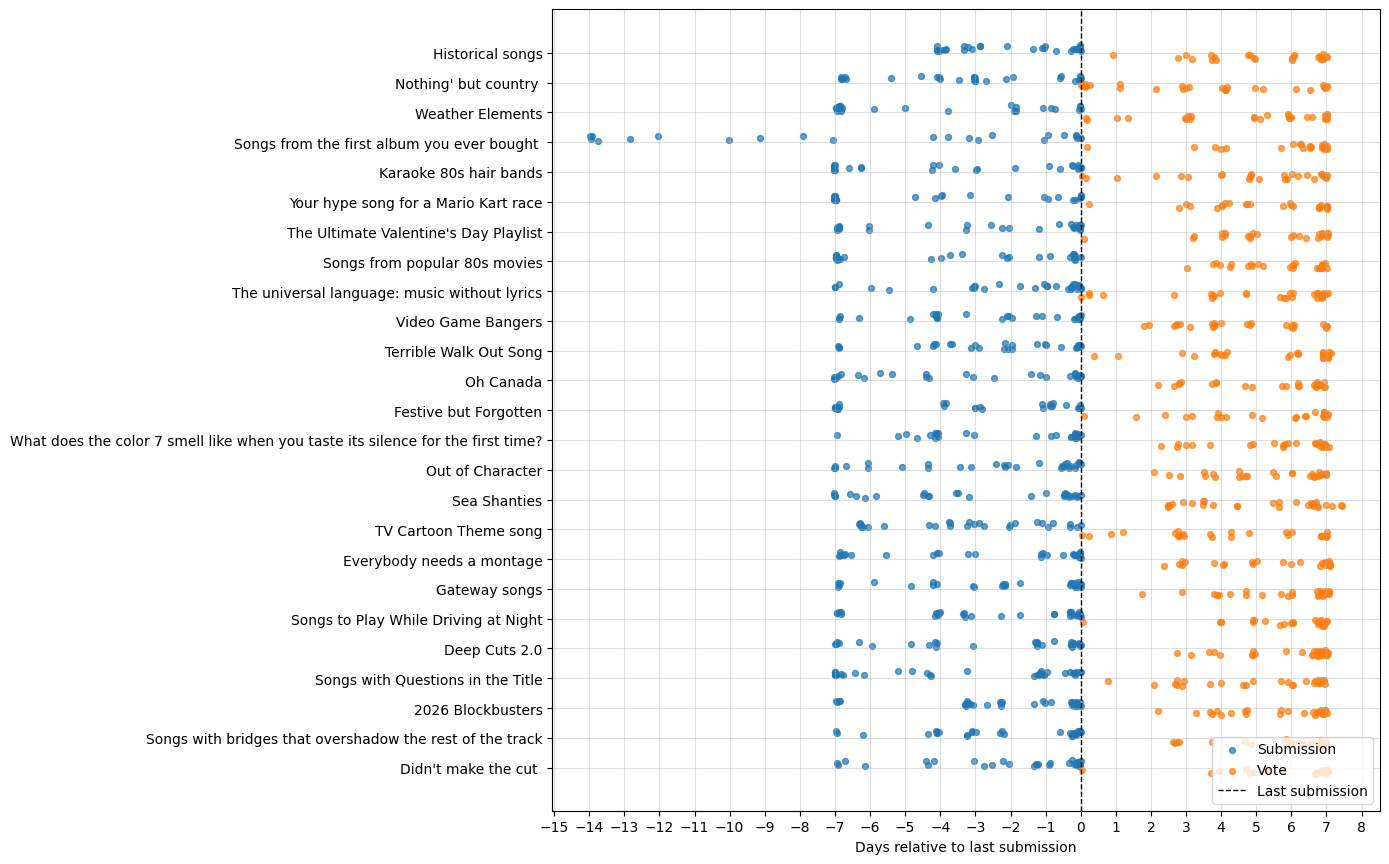

In [37]:
#@title Submission & Voting Timing
import numpy as np
from matplotlib.ticker import MultipleLocator

subs = submissions_df[['Round ID', 'Created']].copy()
subs['Created'] = pd.to_datetime(subs['Created'], utc=True)
votes = votes_df[['Round ID', 'Voter ID', 'Created']].copy()
votes['Created'] = pd.to_datetime(votes['Created'], utc=True)
votes = votes.groupby(['Round ID', 'Voter ID'], as_index=False)['Created'].max()

# Anchor every round on its last submission (time 0)
last_sub = subs.groupby('Round ID')['Created'].max().rename('Last submission')
subs = subs.join(last_sub, on='Round ID')
votes = votes.join(last_sub, on='Round ID').dropna(subset=['Last submission'])
subs['Days'] = (subs['Created'] - subs['Last submission']).dt.total_seconds() / 86400
votes['Days'] = (votes['Created'] - votes['Last submission']).dt.total_seconds() / 86400

# Sort the rounds
rounds_unique = rounds_df.drop_duplicates('ID').set_index('ID')
round_dates = pd.to_datetime(rounds_unique['Created'], utc=True)
round_dates = round_dates.reindex(last_sub.index).fillna(subs.groupby('Round ID')['Created'].min())
round_order = round_dates.sort_values().index
y_pos = {r: i for i, r in enumerate(round_order)}          # <-- was missing
round_names = {r: f'Round {i + 1}' for i, r in enumerate(round_order)}
round_names.update(rounds_unique['Name'].to_dict())

fig, ax = plt.subplots(figsize=(14, max(4, 0.35 * len(round_order))))

# Jittered points: submissions slightly above each row, votes slightly below
rng = np.random.default_rng(0)
ax.scatter(subs['Days'], subs['Round ID'].map(y_pos) - 0.15 + rng.uniform(-0.1, 0.1, len(subs)),
           s=18, alpha=0.7, label='Submission')
ax.scatter(votes['Days'], votes['Round ID'].map(y_pos) + 0.15 + rng.uniform(-0.1, 0.1, len(votes)),
           s=18, alpha=0.7, label='Vote')
ax.axvline(0, color='black', linestyle='--', linewidth=1, label='Last submission')

ax.set_yticks(range(len(round_order)))
ax.set_yticklabels([round_names.get(r, r) for r in round_order])
ax.invert_yaxis()
ax.xaxis.set_major_locator(MultipleLocator(1))  # a gridline every day
ax.set_xlabel('Days relative to last submission')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.4)

plt.tight_layout()
plt.show()

Ordered by: Data order
Songs: 728   Rounds: 25
Spearman ρ = -0.105   p = 0.004   (significant)
First → last song: -3.80 points vs. round average

     mean   sem  count
Bin                   
1    1.61  0.77    190
2    1.40  0.88    181
3   -1.73  0.77    173
4   -1.41  0.79    184


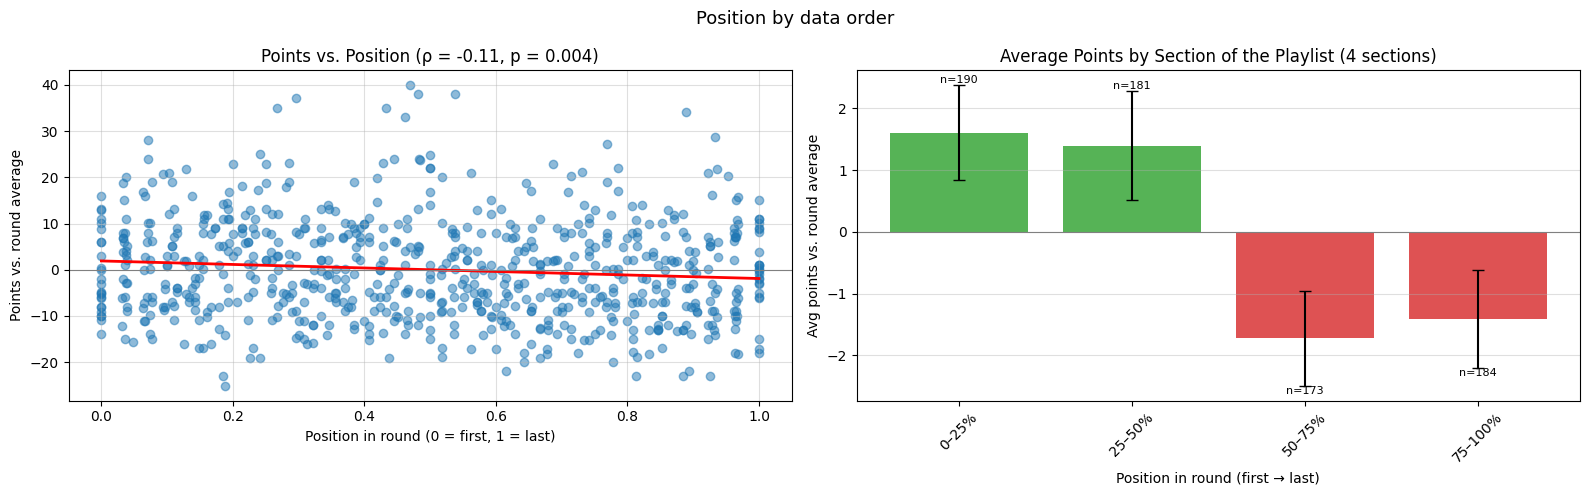

In [39]:
#@title Points vs Time Submited/Playlist position
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

order_by = "Data order"  #@param ["Submission time", "Data order"]
n_bins = 4  #@param {type:"slider", min:2, max:20, step:1}

# Total points per song
points = (votes_df.groupby(['Round ID', 'Spotify URI'])['Points Assigned']
          .sum().rename('Points').reset_index())

# Position of each song within its round (1 = first)
df = submissions_df[['Round ID', 'Spotify URI', 'Created']].copy()
if order_by == "Submission time":
    df['Created'] = pd.to_datetime(df['Created'])
    df['Position'] = df.groupby('Round ID')['Created'].rank(method='first')
else:
    # Order the rows appear in submissions_df
    df['Position'] = df.groupby('Round ID').cumcount() + 1

# Scale position to 0 (first) to 1 (last) so rounds of different sizes line up
size = df.groupby('Round ID')['Position'].transform('max')
df['Rel Pos'] = (df['Position'] - 1) / (size - 1).clip(lower=1)

# Songs with no votes get 0 points
df = df.merge(points, on=['Round ID', 'Spotify URI'], how='left').fillna({'Points': 0})

# Points relative to the round average, so rounds with more points don't skew the result
df['Points vs Avg'] = df['Points'] - df.groupby('Round ID')['Points'].transform('mean')

# Correlation and trend
rho, p = stats.spearmanr(df['Rel Pos'], df['Points vs Avg'])
slope, intercept = np.polyfit(df['Rel Pos'], df['Points vs Avg'], 1)

# Average by section of the playlist (1 = first section, n_bins = last)
df['Bin'] = pd.cut(df['Rel Pos'], bins=np.linspace(0, 1, n_bins + 1),
                   labels=range(1, n_bins + 1), include_lowest=True)
by_bin = df.groupby('Bin', observed=True)['Points vs Avg'].agg(['mean', 'sem', 'count'])

print(f'Ordered by: {order_by}')
print(f'Songs: {len(df)}   Rounds: {df["Round ID"].nunique()}')
print(f'Spearman ρ = {rho:+.3f}   p = {p:.3f}   '
      f'({"significant" if p < 0.05 else "not significant"})')
print(f'First → last song: {slope:+.2f} points vs. round average\n')
print(by_bin.round(2))

# Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle(f'Position by {order_by.lower()}', fontsize=13)

# Left: scatter with trend line
ax1.scatter(df['Rel Pos'], df['Points vs Avg'], alpha=0.5)
ax1.plot([0, 1], [intercept, slope + intercept], color='red', linewidth=2)
ax1.axhline(0, color='gray', linewidth=0.8)
ax1.set_xlabel('Position in round (0 = first, 1 = last)')
ax1.set_ylabel('Points vs. round average')
ax1.set_title(f'Points vs. Position (ρ = {rho:+.2f}, p = {p:.3f})')
ax1.grid(True, alpha=0.4)

# Right: average by section
x = by_bin.index.astype(int)
colors = ['tab:green' if m >= 0 else 'tab:red' for m in by_bin['mean']]
ax2.bar(x, by_bin['mean'], yerr=by_bin['sem'], capsize=4, color=colors, alpha=0.8)
ax2.axhline(0, color='gray', linewidth=0.8)
for xi, (m, s, n) in zip(x, by_bin.values):
    ax2.text(xi, m + (s if m >= 0 else -s), f'n={int(n)}',
             ha='center', va='bottom' if m >= 0 else 'top', fontsize=8)
ax2.set_xticks(range(1, n_bins + 1))
ax2.set_xticklabels([f'{100*(i-1)/n_bins:.0f}–{100*i/n_bins:.0f}%'
                     for i in range(1, n_bins + 1)], rotation=45)
ax2.set_xlabel('Position in round (first → last)')
ax2.set_ylabel('Avg points vs. round average')
ax2.set_title(f'Average Points by Section of the Playlist ({n_bins} sections)')
ax2.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
plt.show()

*italicized text*

# Head-to-Head

In [40]:
 #@title Interactive Running Total of Votes Received { run: "auto" }
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio

# 1. Sort rounds chronologically
sorted_rounds = rounds_df.sort_values(by='Created').reset_index(drop=True)
round_order = {r_id: idx for idx, r_id in enumerate(sorted_rounds['ID'])}
round_names = dict(zip(rounds_df['ID'], rounds_df['Name']))

# 2. Get sorted list of names for reference if needed
all_player_names = sorted(competitors_df['Name'].unique(), key=lambda s: s.lower())

# 3. Colab Form Parameter Dropdowns
Player_1 = "De Wolfe" #@param ['Adam Kestian', 'Ali N.', 'Andrew', 'Andy Curtis', 'Brigette', 'chlo', 'Chris Hogg', 'Chris Kramer', 'd13 m4sch1n3', 'darkknave', 'De Wolfe', 'Devin', 'Dr. Funkenstein', 'Erik Germain', 'Ethan Varghese', 'Hman', 'Isaiah Freed', 'James Roose', 'jammbler', 'jandrews', 'JustLisa', 'Katie', 'katspjs', 'KLee', 'mandeepkundal', 'Mariah', 'Matoos', 'mcapewell', 'Mick', 'Mike', 'Pascal', 'peter mccomb', 'Puneesh', 'shannon_ar', 'Syd', 'the only John', 'theotherotherotherotherchris', 'Wesley', 'William Dullemond', 'Zach']
Player_2 = "mcapewell" #@param ['None', 'Adam Kestian', 'Ali N.', 'Andrew', 'Andy Curtis', 'Brigette', 'chlo', 'Chris Hogg', 'Chris Kramer', 'd13 m4sch1n3', 'darkknave', 'De Wolfe', 'Devin', 'Dr. Funkenstein', 'Erik Germain', 'Ethan Varghese', 'Hman', 'Isaiah Freed', 'James Roose', 'jammbler', 'jandrews', 'JustLisa', 'Katie', 'katspjs', 'KLee', 'mandeepkundal', 'Mariah', 'Matoos', 'mcapewell', 'Mick', 'Mike', 'Pascal', 'peter mccomb', 'Puneesh', 'shannon_ar', 'Syd', 'the only John', 'theotherotherotherotherchris', 'Wesley', 'William Dullemond', 'Zach']
Player_3 = "William Dullemond" #@param ['None', 'Adam Kestian', 'Ali N.', 'Andrew', 'Andy Curtis', 'Brigette', 'chlo', 'Chris Hogg', 'Chris Kramer', 'd13 m4sch1n3', 'darkknave', 'De Wolfe', 'Devin', 'Dr. Funkenstein', 'Erik Germain', 'Ethan Varghese', 'Hman', 'Isaiah Freed', 'James Roose', 'jammbler', 'jandrews', 'JustLisa', 'Katie', 'katspjs', 'KLee', 'mandeepkundal', 'Mariah', 'Matoos', 'mcapewell', 'Mick', 'Mike', 'Pascal', 'peter mccomb', 'Puneesh', 'shannon_ar', 'Syd', 'the only John', 'theotherotherotherotherchris', 'Wesley', 'William Dullemond', 'Zach']

# Identify selected players
selected_players = []
if Player_1 and Player_1 != 'None':
    selected_players.append(Player_1)
if Player_2 and Player_2 != 'None':
    selected_players.append(Player_2)
if Player_3 and Player_3 != 'None':
    selected_players.append(Player_3)

fig = go.Figure()

for name in selected_players:
    player_row = competitors_df[competitors_df['Name'] == name]
    if player_row.empty:
        continue
    p_id = player_row['ID'].values[0]

    # Get all submissions by this player
    p_submissions = submissions_df[submissions_df['Submitter ID'] == p_id].copy()

    # Calculate total votes received per round
    votes_received = votes_df[votes_df['Submitter ID'] == p_id]
    votes_by_round = votes_received.groupby('Round ID')['Points Assigned'].sum().reset_index()

    # Merge submission details with points per round
    merged = pd.merge(p_submissions, votes_by_round, on='Round ID', how='left')
    merged['Points Assigned'] = merged['Points Assigned'].fillna(0)

    # Sort chronologically
    merged['SortRank'] = merged['Round ID'].map(round_order)
    merged['Round Name'] = merged['Round ID'].map(round_names)
    merged = merged.sort_values(by='SortRank').reset_index(drop=True)

    # Calculate cumulative running total
    merged['Running Total'] = merged['Points Assigned'].cumsum()

    # Prepare hover template text
    hover_text = []
    for idx, row in merged.iterrows():
        text = (
            f"<b>Round:</b> {row['Round Name']}<br>"
            f"<b>Song:</b> {row['Title']}<br>"
            f"<b>Artist:</b> {row['Artist(s)']}<br>"
            f"<b>Points in Round:</b> {int(row['Points Assigned'])}<br>"
            f"<b>Running Total:</b> {int(row['Running Total'])}"
        )
        hover_text.append(text)

    fig.add_trace(go.Scatter(
        x=merged['Round Name'],
        y=merged['Running Total'],
        mode='lines+markers',
        name=name,
        text=hover_text,
        hoverinfo='text'
    ))

fig.update_layout(
    title='Running Total of Votes Received Comparison',
    xaxis_title='Round',
    yaxis_title='Cumulative Points',
    hovermode='closest',
    template='plotly_white',
    width=1000,
    height=1000,
    xaxis=dict(tickangle=45)
)

pio.show(fig)

In [ ]:
# @title
